# Clean set of EODs with a clear emitter, all 71 recordings (4-fish, Kaden masks, Denis' model)

The same selection as `EOD_clean_emitter_set_4fish_kaden.ipynb` (5 videos, my model), over all 71 recordings of 2024-02-20.
My model was only run on 5 of them, so **Denis' model** (his analytic pipeline on my mask midline, `denis_predicted_voltages.npz`
and `denis_assignments.csv`) takes its place. EOD tables: `data/4 fish/Data_4fish_2024-02-20T<t>.csv` (re-synchronised, no
frame offset); masks: Kaden's tracking.

An EOD is given to fish f when **all** of these hold:
1. **good masks**: the frame passes the mask QC for all four fish (`kaden_mask_qc.py`, `mask_qc_good_frames.csv`);
2. **isolated**: f's mask midline is ≥ 10 cm from every other fish's midline;
3. **shape**: f has the lowest shape L2 of the four fish in Denis' model (his predicted and recorded peak-to-peak patterns each
   scaled to max |v| = 1 over the 10 pairs: `fish | Denis, L2 (max |v| = 1)`);
4. **recorded amplitude on f's nearest pairs**: f's 2 nearest electrode pairs (distance from f's midline to the nearer pole of each
   pair) are the 2 pairs with the largest recorded |peak-to-peak|, with the sign Denis' model predicts for f on both;
5. **other fish weaker there**: on each of those 2 pairs, f's predicted |v| in Denis' model is ≥ 2× that of every other fish.

From the EODs that pass, 3 per fish and nearest pair are drawn at random (seed 0), one per video first where possible and at least
100 frames apart within a video.

In [1]:
import os, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle
from matplotlib.backends.backend_pdf import PdfPages
from model_voltages_4fish import Masks                                # imports mask_metrics, which sets the Agg backend
from eod_assign import load_electrode_pairs, recorded_pair_traces_all
from kaden_4fish_assign import kaden_pkl
%matplotlib inline

BASE, LET, P = 'results/eod_assign_4fish_kaden', 'ABCD', 912
OUT = f'{BASE}/clean_emitter_set_71'; os.makedirs(f'{OUT}/per_frame', exist_ok=True)
ELECTRODES = 'data/electrodes/electrodes_signed_px_coord_4-fish.csv'
EL = pd.read_csv(ELECTRODES).sort_values('pair').reset_index(drop=True)
PIDS = [p for p, _, _ in load_electrode_pairs(ELECTRODES, P)]
PX_CM = P / 60
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E'}
L_CM = {'A': 15.65, 'B': 13.10, 'C': 9.82, 'D': 8.51}
ISO_CM, K_NEAR, DOM, PER_CELL, MIN_DF = 10, 2, 2, 3, 100
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
ELXY = np.concatenate([EL[['y1', 'x1']].to_numpy(float), EL[['y2', 'x2']].to_numpy(float)]) / PX_CM   # (20, row/col) cm
RECS = sorted(os.path.basename(os.path.dirname(p)) for p in glob.glob(f'{BASE}/*/denis_predicted_voltages.npz'))
NO_QC = [t for t in RECS if not os.path.exists(f'{BASE}/{t}/mask_qc_good_frames.csv')]
print(f'{len(RECS)} recordings; without mask QC (left out): {NO_QC}')

rows, n_eod, t0 = [], {}, time.time()
for t in RECS:
    if t in NO_QC: continue
    A = pd.read_csv(f'{BASE}/{t}/denis_assignments.csv', usecols=['row', 'Frame', 'fish | Denis, L2 (max |v| = 1)'] + [f'L2 {f} (max |v| = 1)' for f in LET])
    z = np.load(f'{BASE}/{t}/denis_predicted_voltages.npz', allow_pickle=True)
    assert (A.Frame.to_numpy() == z['frame']).all(); n_eod[t] = len(A)
    good = set(pd.read_csv(f'{BASE}/{t}/mask_qc_good_frames.csv').frame)
    mz = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); mids_all = mz['mids']; gi = {int(k): i for i, k in enumerate(mz['frames'])}
    sel = np.flatnonzero([(int(k) in good) and (int(k) in gi) for k in A.Frame])
    A = A.iloc[sel]; R = z['recorded_ptp'][sel]; M = z['predicted_ptp'][sel]
    xy = mids_all[[gi[int(k)] for k in A.Frame]] * (P - 1) / PX_CM; del mids_all
    ok = np.isfinite(xy).all((1, 2, 3)) & np.isfinite(M).all((1, 2)) & np.isfinite(R).all(1)
    A, R, M, xy, sel = A[ok], R[ok], M[ok], xy[ok], sel[ok]; n = len(A); ii = np.arange(n)
    if n == 0: continue
    L2 = A[[f'L2 {f} (max |v| = 1)' for f in LET]].to_numpy()
    sub = xy[:, :, ::5]; G = np.full((n, 4, 4), np.inf)
    for f in range(4):
        for h in range(f + 1, 4):
            G[:, f, h] = G[:, h, f] = np.linalg.norm(sub[:, f, :, None] - sub[:, h, None], axis=-1).min((1, 2))
    top_rec = np.argsort(-np.abs(R), 1)
    pick = A['fish | Denis, L2 (max |v| = 1)'].fillna('').to_numpy()
    for f in range(4):
        iso = G[:, f].min(1) >= ISO_CM
        if not iso.any(): continue
        de = np.linalg.norm(xy[:, f, :, None] - ELXY[None, None], axis=-1).min(1)
        DE = np.minimum(de[:, :10], de[:, 10:]); near = np.argsort(DE, 1); nk = near[:, :K_NEAR]
        own = np.abs(M[ii[:, None], f, nk]); oth = np.max([np.abs(M[ii[:, None], h, nk]) for h in range(4) if h != f], 0)
        rows.append(pd.DataFrame(dict(
            video=t, row=sel, Frame=A.Frame.to_numpy(), fish=LET[f], gap_cm=G[:, f].min(1), iso=iso,
            shape_ok=pick == LET[f], L2_fish=L2[:, f], L2_next_best=np.sort(np.delete(L2, f, 1), 1)[:, 0],
            nearest_pair=near[:, 0] + 1, second_pair=near[:, 1] + 1, dist_nearest_cm=DE[ii, near[:, 0]], dist_second_cm=DE[ii, near[:, 1]],
            rec_top3_pairs=[','.join(map(str, r[:3] + 1)) for r in top_rec], rec_max_V=np.abs(R).max(1),
            top_ok=[set(a[:K_NEAR]) == set(b[:K_NEAR]) for a, b in zip(near, top_rec)],
            sign_ok=(np.sign(R[ii[:, None], nk]) == np.sign(M[ii[:, None], f, nk])).all(1),
            dom_min=(own / oth).min(1)))[iso])
print(f'candidates built in {(time.time() - t0) / 60:.1f} min')
D = pd.concat(rows, ignore_index=True)
c = {'2. isolated ≥ 10 cm (good masks)': np.ones(len(D), bool)}
c['3. + lowest shape L2 (Denis)'] = D.shape_ok.to_numpy()
c['4. + recorded top-2 = 2 nearest pairs, model sign'] = c['3. + lowest shape L2 (Denis)'] & D.top_ok & D.sign_ok
c[f'5. + others ≤ 1/{DOM} of its predicted |v| there'] = c['4. + recorded top-2 = 2 nearest pairs, model sign'] & (D.dom_min >= DOM)
FUNNEL = pd.DataFrame({k: D[v].groupby('fish').size() for k, v in c.items()}).T.fillna(0).astype(int); FUNNEL['all'] = FUNNEL.sum(1)
print(f'{sum(n_eod.values())} EODs in the {len(n_eod)} recordings with mask QC; fish-EODs passing each step (cumulative):'); display(FUNNEL)
PASS = D[c[f'5. + others ≤ 1/{DOM} of its predicted |v| there']].reset_index(drop=True)
PASS.to_csv(f'{OUT}/clean_emitter_all_passing_71.csv', index=False)
print('passing EODs per fish × nearest pair:'); display(pd.crosstab(PASS.fish, PASS.nearest_pair, margins=True))
print('passing EODs per fish × recording hour:'); display(pd.crosstab(PASS.fish, PASS.video.str[:2], margins=True))

71 recordings; without mask QC (left out): []


candidates built in 7.4 min


3667494 EODs in the 71 recordings with mask QC; fish-EODs passing each step (cumulative):


fish,A,B,C,D,all
2. isolated ≥ 10 cm (good masks),249178,883293,501312,332654,1966437
3. + lowest shape L2 (Denis),90901,145689,114763,75550,426903
"4. + recorded top-2 = 2 nearest pairs, model sign",23143,31765,37744,15571,108223
5. + others ≤ 1/2 of its predicted |v| there,14634,24297,24055,3393,66379


passing EODs per fish × nearest pair:


nearest_pair,1,2,3,4,5,6,7,8,9,10,All
fish,,,,,,,,,,,
A,676,411,744,841,3227,4287,1521,1563,330,1034,14634
B,9078,2231,3579,69,2,823,1910,3972,1334,1299,24297
C,101,1188,1636,292,369,3409,2530,1364,26,13140,24055
D,101,149,291,261,349,865,499,206,17,655,3393
All,9956,3979,6250,1463,3947,9384,6460,7105,1707,16128,66379


passing EODs per fish × recording hour:


video,00,01,02,03,04,05,06,07,08,09,...,15,16,17,18,19,20,21,22,23,All
fish,,,,,,,,,,,,,,,,,,,,,
A,1653,2069,1589,999,674,634,477,212,234,128,...,67,41,436,611,244,949,978,1374,984,14634
B,165,337,356,1661,212,97,565,435,531,1102,...,1010,450,184,2410,734,662,2683,2008,2427,24297
C,1770,5016,1667,1243,1306,1933,78,291,2919,917,...,124,188,195,357,367,245,496,1681,1743,24055
D,176,348,396,176,137,365,82,455,119,135,...,0,12,96,42,78,169,168,0,8,3393
All,3764,7770,4008,4079,2329,3029,1202,1393,3803,2282,...,1201,691,911,3420,1423,2025,4325,5063,5162,66379


In [2]:
rng = np.random.default_rng(0)
pick = []
for (f, p), g in PASS.groupby(['fish', 'nearest_pair']):
    g = g.iloc[rng.permutation(len(g))]; chosen = []
    for rnd in range(2):                                                  # first pass: one per video; second: fill up
        for _, r in g.iterrows():
            if len(chosen) == PER_CELL: break
            if any(r.video == q.video and r.Frame == q.Frame and r.row == q.row for q in chosen): continue
            if rnd == 0 and any(r.video == q.video for q in chosen): continue
            if any(r.video == q.video and abs(r.Frame - q.Frame) < MIN_DF for q in chosen): continue
            chosen.append(r)
    pick += chosen
PK = pd.DataFrame(pick).sort_values(['fish', 'nearest_pair', 'video', 'Frame']).reset_index(drop=True)
PK.to_csv(f'{OUT}/clean_emitter_set_71.csv', index=False)
print(f'{len(PK)} EODs picked from {PK.video.nunique()} recordings'); display(pd.crosstab(PK.fish, PK.nearest_pair, margins=True))
display(PK[['video', 'Frame', 'row', 'fish', 'nearest_pair', 'second_pair', 'dist_nearest_cm', 'dist_second_cm', 'gap_cm',
            'L2_fish', 'L2_next_best', 'dom_min', 'rec_top3_pairs', 'rec_max_V']].round(3))

119 EODs picked from 48 recordings


nearest_pair,1,2,3,4,5,6,7,8,9,10,All
fish,,,,,,,,,,,
A,3,3,3,3,3,3,3,3,3,3,30
B,3,3,3,3,2,3,3,3,3,3,29
C,3,3,3,3,3,3,3,3,3,3,30
D,3,3,3,3,3,3,3,3,3,3,30
All,12,12,12,12,11,12,12,12,12,12,119


,video,Frame,row,fish,nearest_pair,second_pair,dist_nearest_cm,dist_second_cm,gap_cm,L2_fish,L2_next_best,dom_min,rec_top3_pairs,rec_max_V
0,03_52_54,21029,16179,A,1,9,4.215,6.552,23.772,0.116,1.698,3.727,"1,9,8",0.156
1,20_16_25,25869,28721,A,1,9,0.708,2.042,14.643,0.330,1.961,4.881,"1,9,8",0.218
2,23_36_27,30800,25622,A,1,2,4.847,7.182,30.722,0.630,2.036,6.558,"1,2,9",0.082
3,17_56_24,18639,18624,A,2,1,3.405,3.496,18.421,0.213,1.754,9.919,"2,1,9",0.278
4,20_16_25,26202,29108,A,2,1,1.318,2.022,16.338,0.361,1.600,5.987,"1,2,9",0.303
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,05_32_55,48681,38359,D,9,1,1.408,2.573,31.909,0.309,1.262,2.245,"9,1,10",0.190
115,05_52_55,37795,31939,D,9,1,1.132,2.721,36.904,0.176,1.613,5.667,"9,1,8",0.220
116,01_52_53,10623,8673,D,10,2,1.171,1.870,31.587,0.281,1.957,10.351,"2,10,3",0.104
117,09_32_57,53684,46419,D,10,6,2.469,3.031,33.367,0.325,1.997,5.704,"6,10,7",0.209


## One figure per picked EOD

- **tank** (top left): Kaden's masks of that frame, each fish in its colour; the emitter in a dashed box; electrodes (+ filled,
  − open, pair number at the + pole); the emitter's 2 nearest pairs joined by a line.
- **zooms** (top right): each fish's mask with its midline (head = dot), other fish grey, 2 cm scale bar.
- **shape** (bottom left): Denis' model, recorded peak-to-peak and every fish's prediction each scaled to max |v| = 1 (legend:
  shape L2); grey bands: the emitter's 2 nearest pairs.
- **predicted |v|** (bottom middle): every fish's |v| in Denis' model on the emitter's 2 nearest pairs (criterion 5).
- **recorded traces** (bottom right): the 25 samples of all 10 pairs (demeaned, volts); the 2 nearest pairs in the emitter's
  colour.

All figures are in `per_frame/` and one PDF per fish; the first one of each fish is shown here.

loaded 119 frames


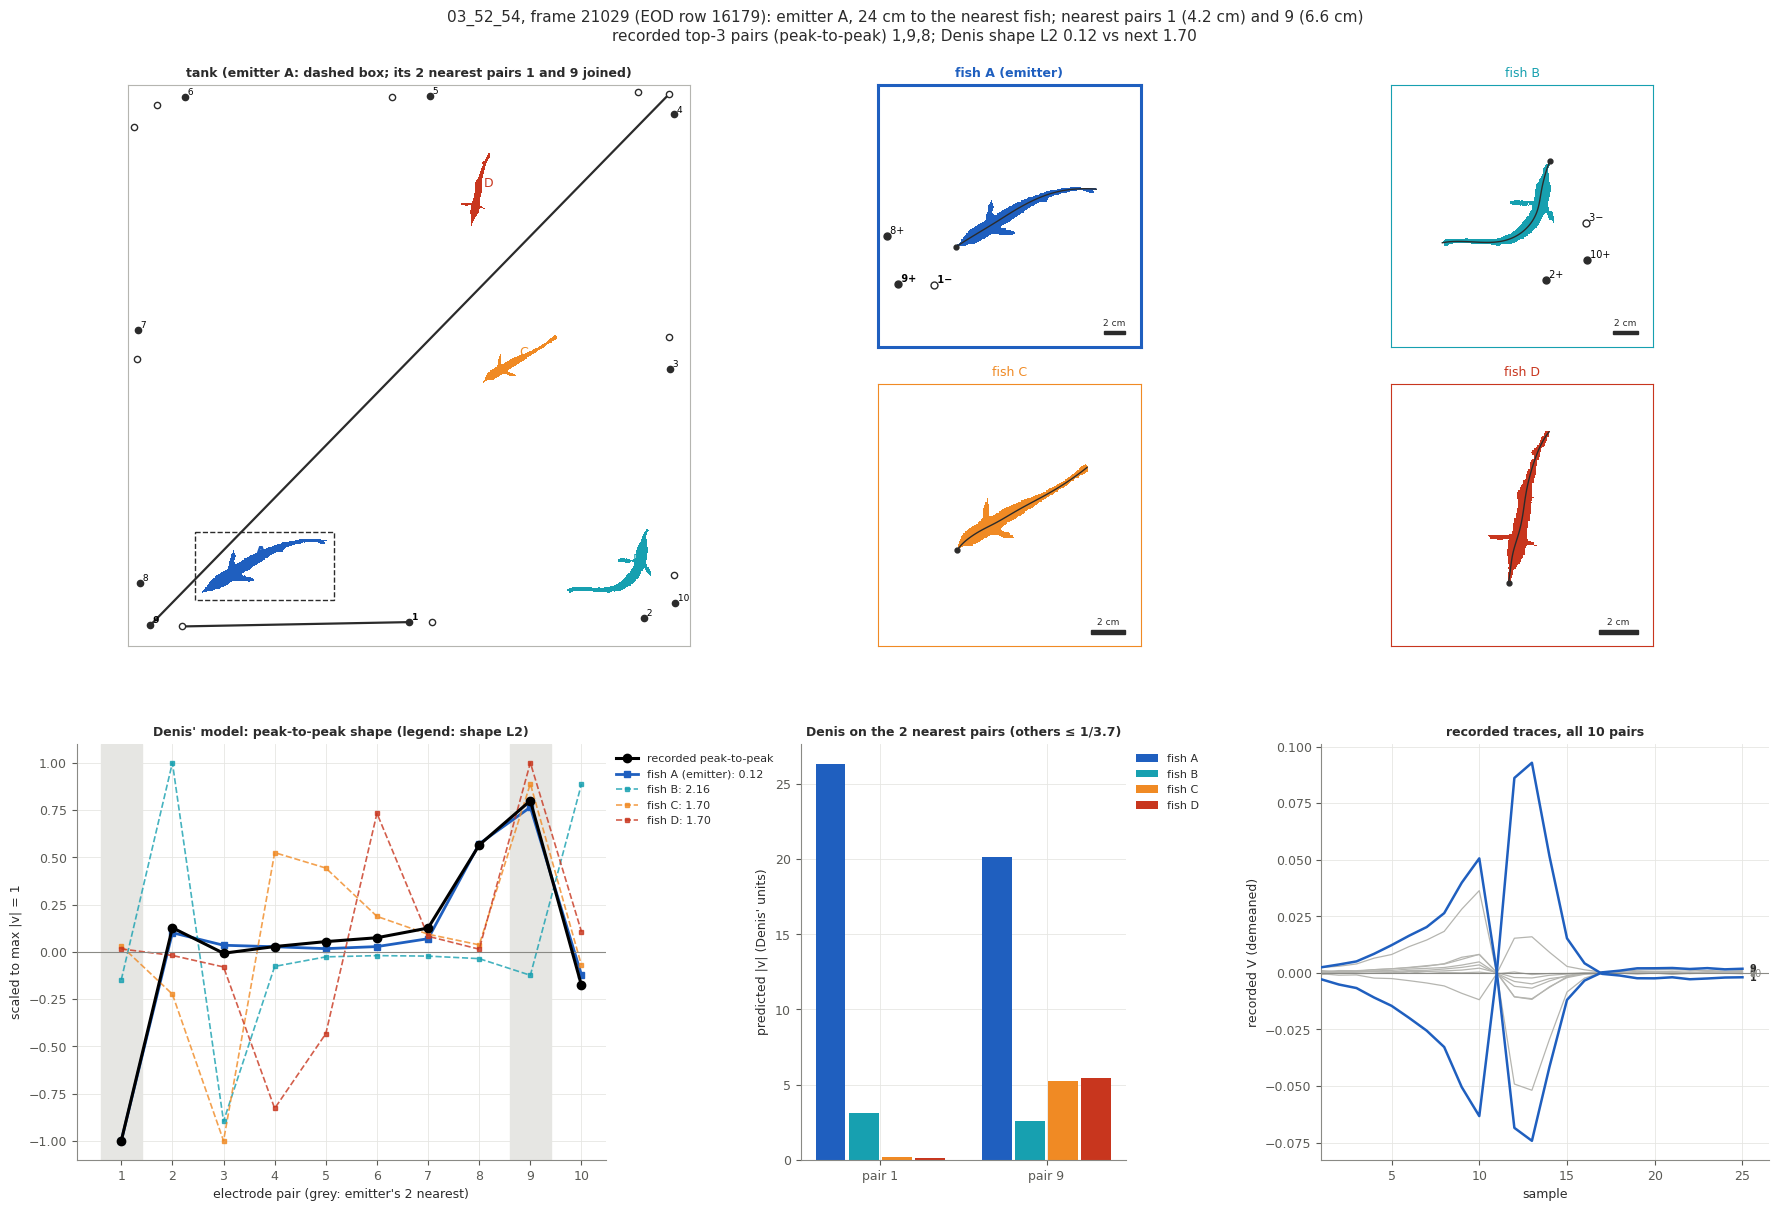

fish A: 30 figures -> results/eod_assign_4fish_kaden/clean_emitter_set_71/clean_emitter_set_71_fish_A.pdf


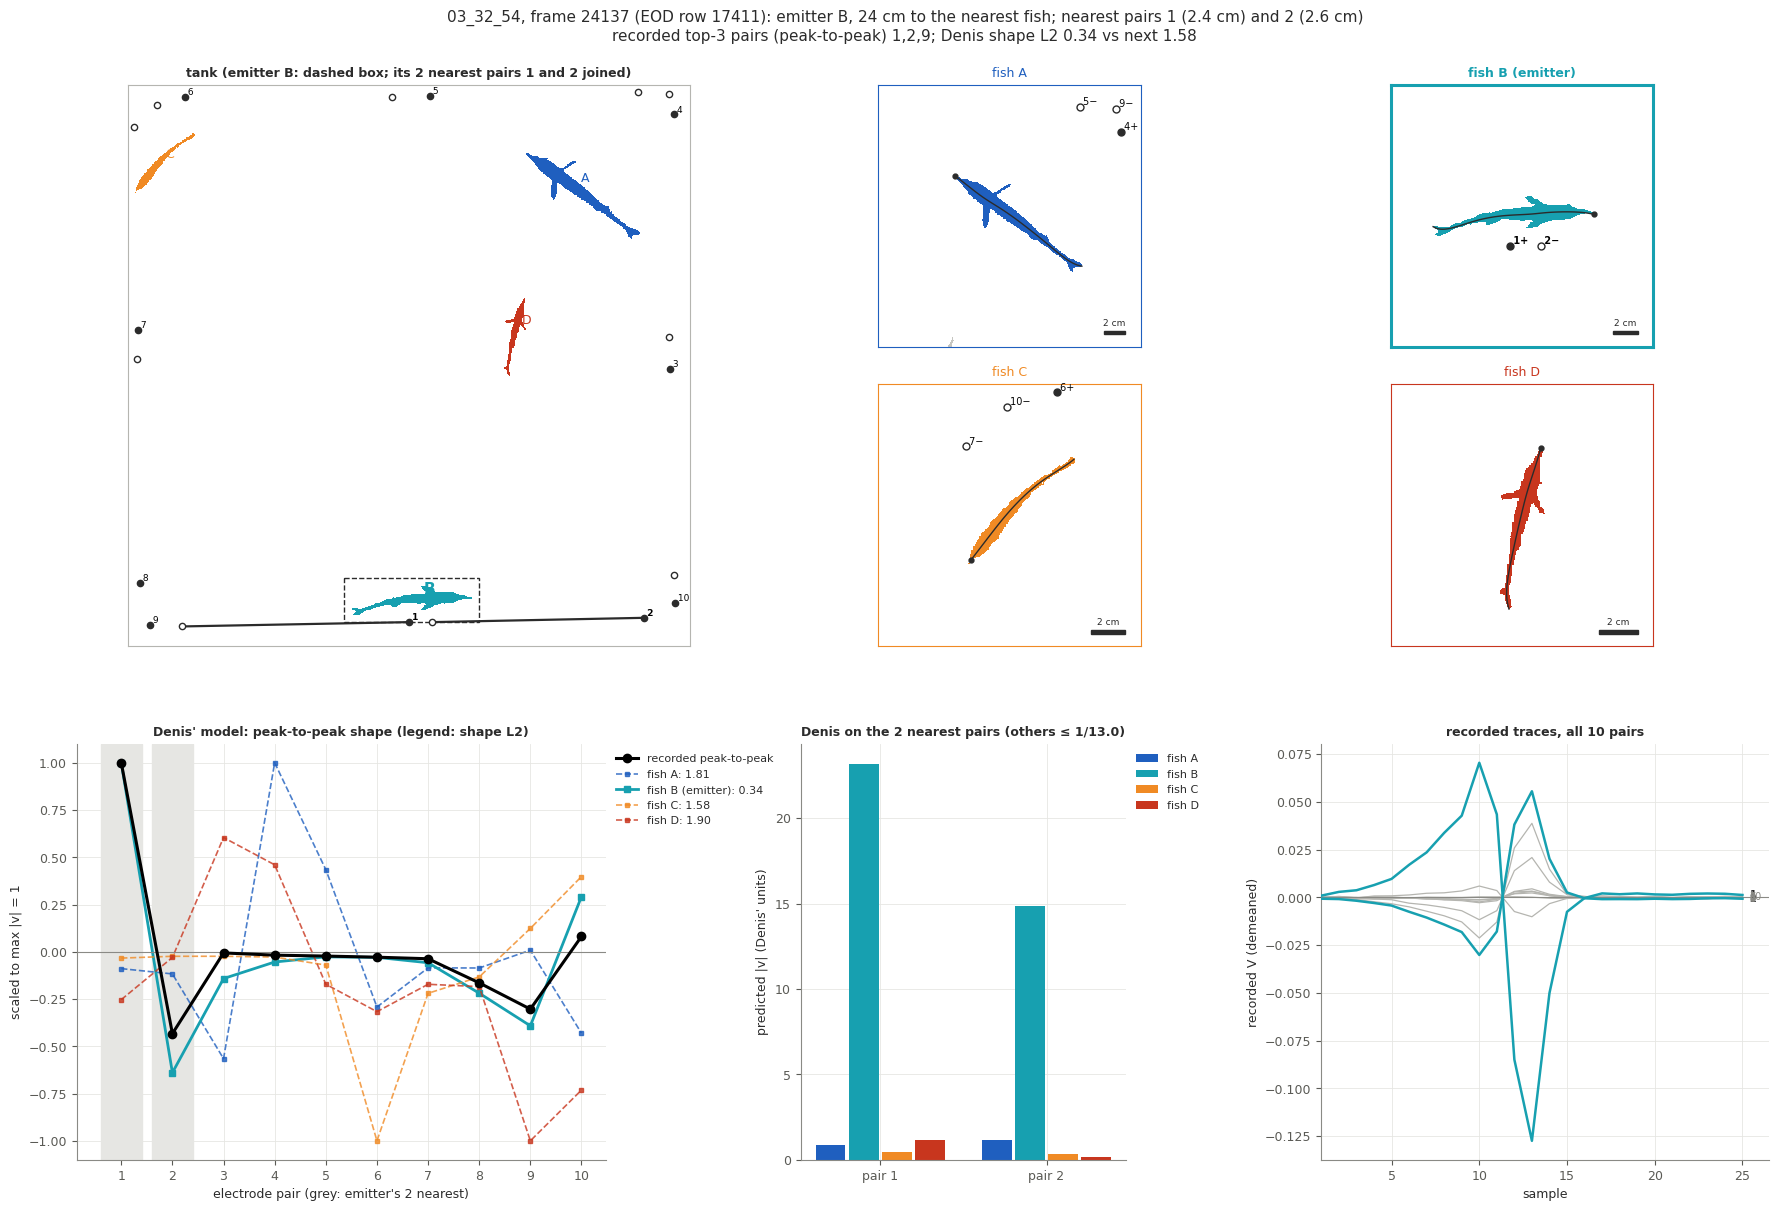

fish B: 29 figures -> results/eod_assign_4fish_kaden/clean_emitter_set_71/clean_emitter_set_71_fish_B.pdf


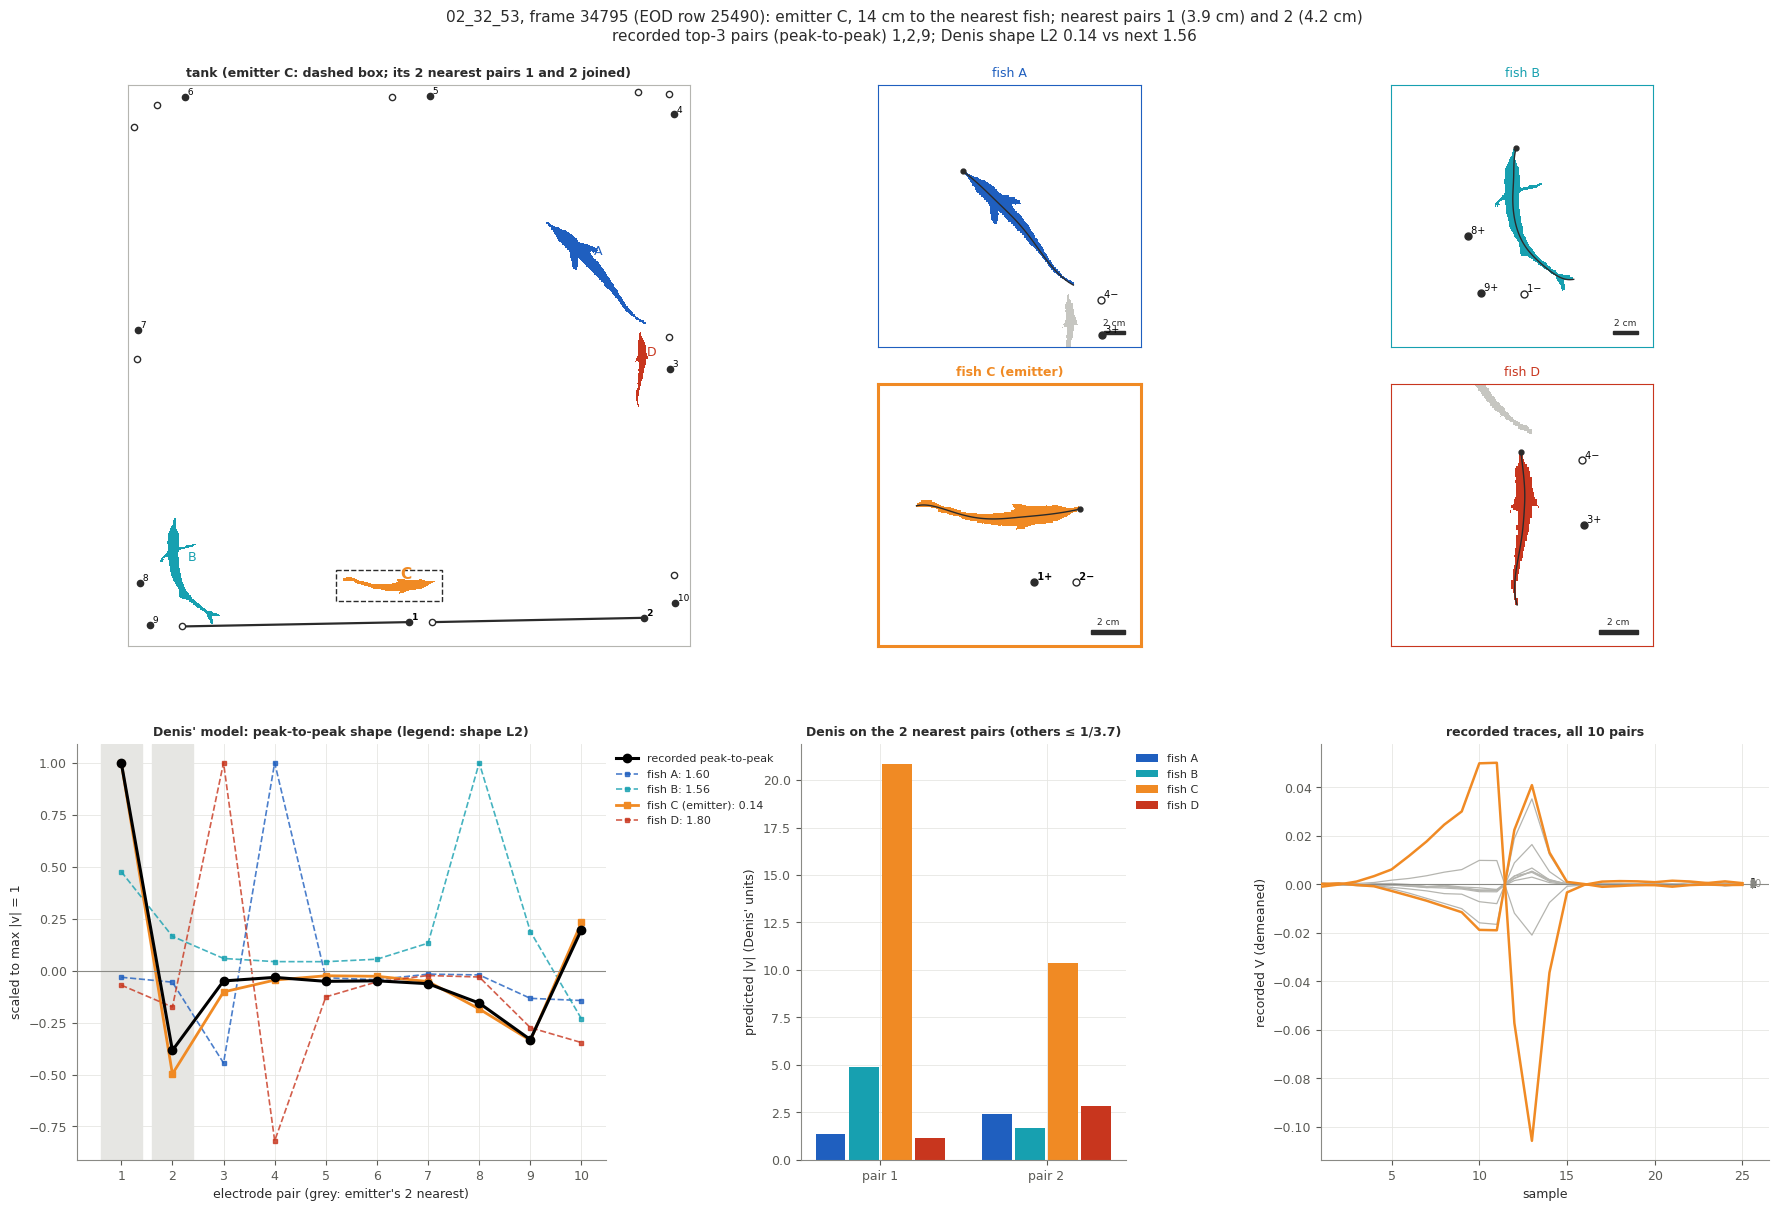

fish C: 30 figures -> results/eod_assign_4fish_kaden/clean_emitter_set_71/clean_emitter_set_71_fish_C.pdf


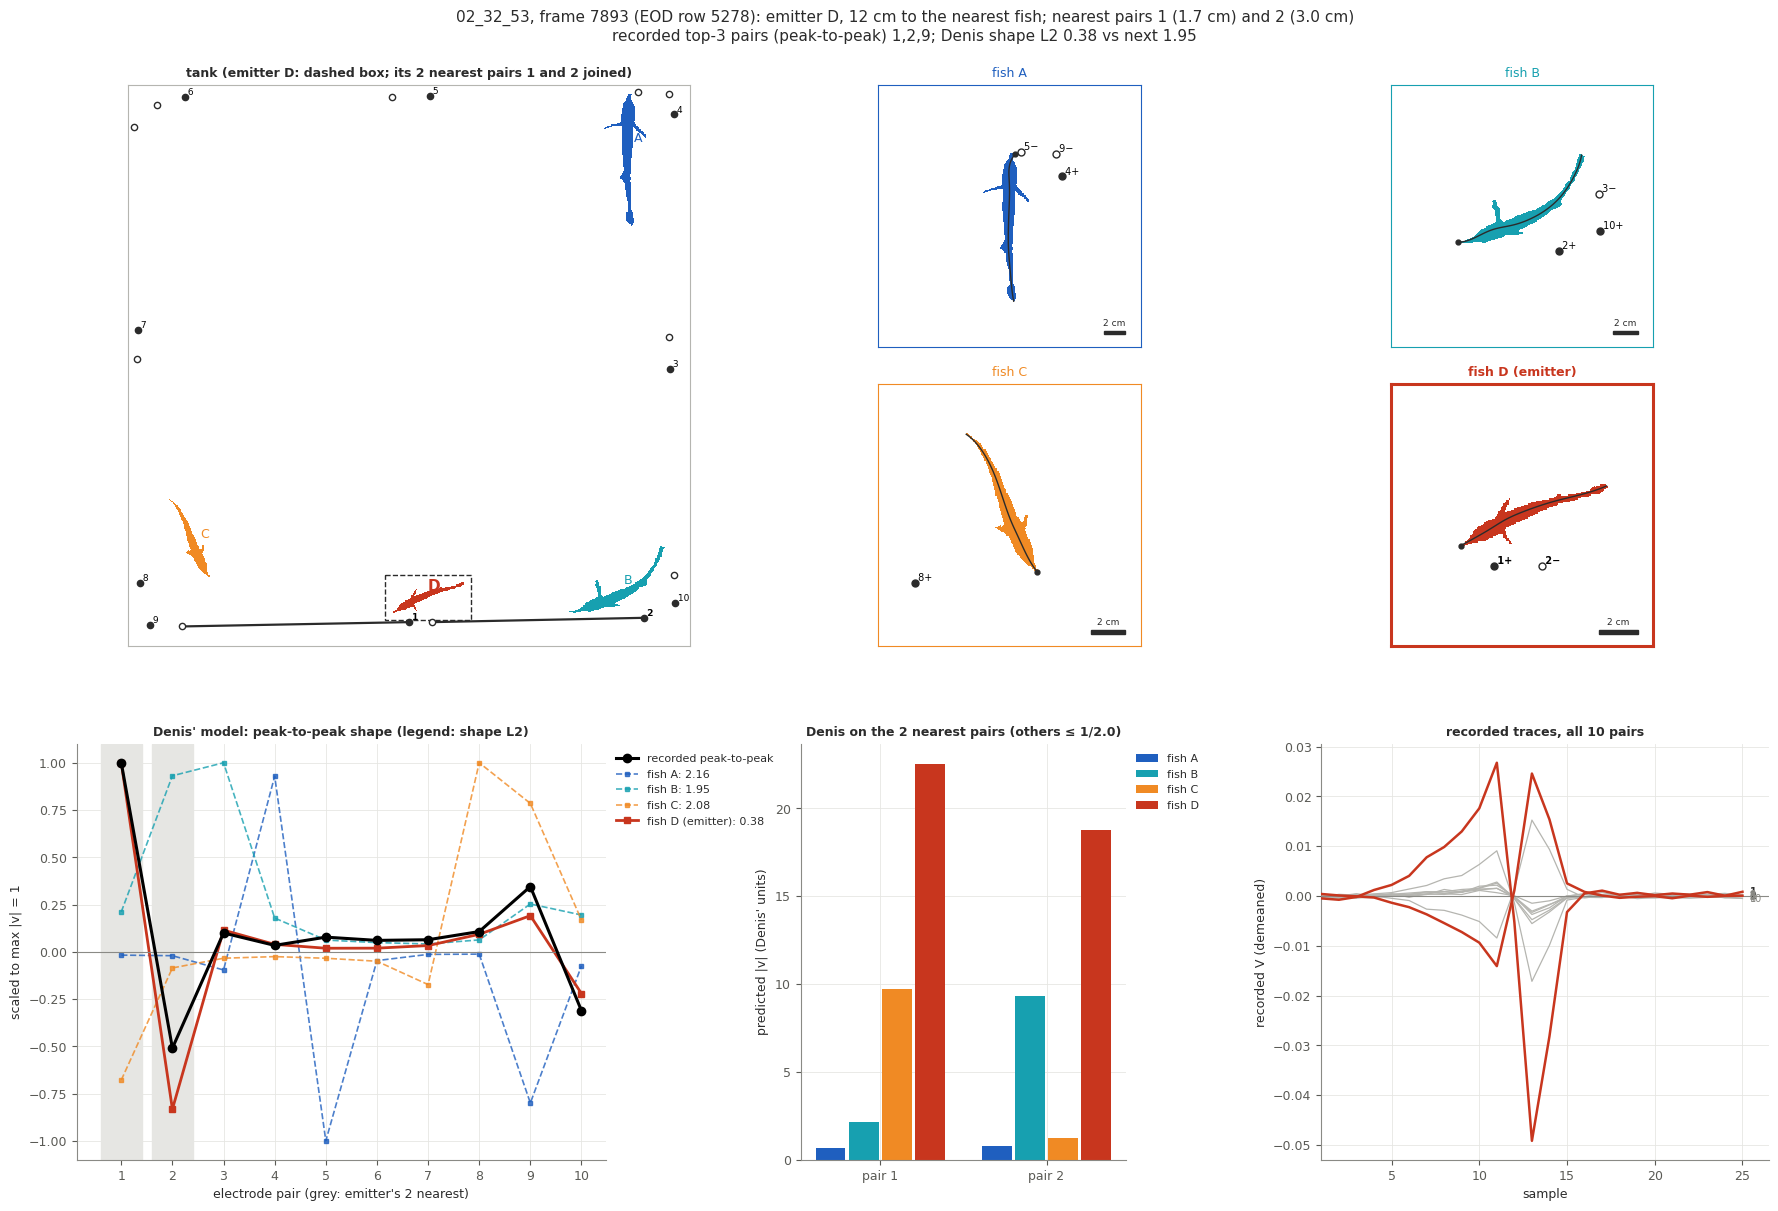

fish D: 30 figures -> results/eod_assign_4fish_kaden/clean_emitter_set_71/clean_emitter_set_71_fish_D.pdf


In [3]:
masks, mids, TR, DREC, DPRED = {}, {}, {}, {}, {}
for t in PK.video.unique():
    g = PK[PK.video == t]
    mk = Masks(dict(identity='kaden', masks=kaden_pkl(t)))
    for k in g.Frame.unique(): masks[(t, int(k))] = mk(int(k))
    del mk
    z = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); idx = {int(k): i for i, k in enumerate(z['frames'])}; mm_ = z['mids']
    for k in g.Frame.unique(): mids[(t, int(k))] = mm_[idx[int(k)]] * (P - 1)
    rows = np.sort(g.row.to_numpy()); keep = set(rows.tolist())
    df = pd.read_csv(f'data/4 fish/Data_4fish_2024-02-20T{t}.csv', usecols=[f'electrode_{p}_time_{i}' for p in PIDS for i in range(1, 26)],
                     skiprows=lambda i: i > 0 and (i - 1) not in keep)
    Vt = recorded_pair_traces_all(df, PIDS, 25); del df
    dv = np.load(f'{BASE}/{t}/denis_predicted_voltages.npz', allow_pickle=True)
    for k, rw in enumerate(rows):
        TR[(t, int(rw))] = Vt[k]; DREC[(t, int(rw))] = dv['recorded_ptp'][rw]; DPRED[(t, int(rw))] = dv['predicted_ptp'][rw]
print(f'loaded {len(masks)} frames')

def draw_electrodes(ax, hit_pairs, lim=None, fs=6.5, ms=4.5):
    for _, e in EL.iterrows():
        pp = (e.x1, e.y1) if str(e.pol1).strip() == '+' else (e.x2, e.y2)
        mm_ = (e.x2, e.y2) if str(e.pol1).strip() == '+' else (e.x1, e.y1)
        hit = int(e.pair) in hit_pairs
        if lim is None and hit: ax.plot([pp[0], mm_[0]], [pp[1], mm_[1]], color='#2b2b2b', lw=1.6, zorder=2)
        for pt, filled in ((pp, True), (mm_, False)):
            if lim is not None and not (lim[0] <= pt[0] <= lim[1] and lim[2] <= pt[1] <= lim[3]): continue
            ax.plot(*pt, 'o', ms=ms, mfc='#2b2b2b' if filled else 'white', mec='#2b2b2b', mew=1, zorder=3)
            if filled or lim is not None:
                ax.text(pt[0], pt[1], f' {int(e.pair)}' + ('' if lim is None else ('+' if filled else '−')), fontsize=fs,
                        color='#000000', fontweight='bold' if hit else 'normal', va='bottom', zorder=3)

def tank(ax, r, m, near):
    img = np.ones((P, P, 3))
    for j, f in enumerate(LET): img[m[j]] = to_rgb(FISH_COL[f])
    ax.imshow(img, origin='upper', extent=(-0.5, P - 0.5, P - 0.5, -0.5), interpolation='nearest')
    for j, f in enumerate(LET):
        if m[j].any():
            yy, xx = np.nonzero(m[j])
            ax.text(xx.mean() + 18, yy.mean() - 18, f, fontsize=11 if f == r.fish else 9, color=FISH_COL[f],
                    fontweight='bold' if f == r.fish else 'normal', ha='center', va='center')
    j = LET.index(r.fish)
    if m[j].any():
        yy, xx = np.nonzero(m[j])
        ax.add_patch(Rectangle((xx.min() - 12, yy.min() - 12), xx.max() - xx.min() + 24, yy.max() - yy.min() + 24, fill=False, ec='#2b2b2b', lw=1, ls='--'))
    draw_electrodes(ax, near)
    ax.set(xlim=(0, P), ylim=(P, 0), xticks=[], yticks=[], aspect='equal'); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color('#b5b5b0')
    ax.set_title(f'tank (emitter {r.fish}: dashed box; its 2 nearest pairs {near[0]} and {near[1]} joined)', fontsize=9)

def zoom(ax, r, m, f, ml, near):
    j = LET.index(f)
    if not m[j].any():
        ax.axis('off'); ax.text(0.5, 0.5, f'fish {f}: no mask', ha='center', transform=ax.transAxes); return
    yy, xx = np.nonzero(m[j]); cy, cx = yy.mean(), xx.mean(); h = 0.8 * L_CM[f] * PX_CM
    x0, x1, y0, y1 = cx - h, cx + h, cy - h, cy + h
    img = np.ones((P, P, 3))
    for jj, g in enumerate(LET): img[m[jj]] = to_rgb(FISH_COL[g]) if g == f else (0.78, 0.78, 0.76)
    ax.imshow(img, origin='upper', extent=(-0.5, P - 0.5, P - 0.5, -0.5), interpolation='nearest')
    if np.isfinite(ml[j]).all():
        ax.plot(ml[j][:, 1], ml[j][:, 0], color='#2b2b2b', lw=1); ax.plot(ml[j][-1, 1], ml[j][-1, 0], 'o', ms=3.5, color='#2b2b2b')
    draw_electrodes(ax, near if f == r.fish else [], lim=(x0, x1, y0, y1), fs=7, ms=5)
    sb = 2 * PX_CM
    ax.add_patch(Rectangle((x1 - 0.06 * 2 * h - sb, y1 - 0.06 * 2 * h), sb, 0.012 * 2 * h, color='#2b2b2b'))
    ax.text(x1 - 0.06 * 2 * h - sb / 2, y1 - 0.075 * 2 * h, '2 cm', fontsize=6.5, ha='center', va='bottom')
    ax.set(xlim=(x0, x1), ylim=(y1, y0), xticks=[], yticks=[], aspect='equal'); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color(FISH_COL[f]); sp.set_linewidth(2.2 if f == r.fish else 0.8)
    ax.set_title(f"fish {f}{' (emitter)' if f == r.fish else ''}", fontsize=9, fontweight='bold' if f == r.fish else 'normal', color=FISH_COL[f])


def bottom(axs_, axp, axt, r, near):
    V = TR[(r.video, int(r.row))]; R = DREC[(r.video, int(r.row))]; Mf = DPRED[(r.video, int(r.row))]; x = np.arange(1, 11)
    axs_.plot(x, R / np.abs(R).max(), '-o', color='#000000', lw=2.2, ms=6, label='recorded peak-to-peak', zorder=5)
    for j, f in enumerate(LET):
        e = f == r.fish; ps = Mf[j] / np.abs(Mf[j]).max(); l2 = np.linalg.norm(R / np.abs(R).max() - ps)
        axs_.plot(x, ps, marker='s', color=FISH_COL[f], lw=2 if e else 1.2, ms=5 if e else 3.5, ls='-' if e else '--', alpha=1 if e else 0.8,
                  label=f'fish {f}{" (emitter)" if e else ""}: {l2:.2f}')
    for p in near: axs_.axvspan(p - 0.4, p + 0.4, color='#e6e6e3', zorder=0)
    axs_.axhline(0, color='#8a8a85', lw=0.8)
    axs_.set(xticks=x, xlabel="electrode pair (grey: emitter's 2 nearest)", ylabel='scaled to max |v| = 1')
    axs_.set_title("Denis' model: peak-to-peak shape (legend: shape L2)", fontsize=9)
    axs_.legend(fontsize=8, frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0))
    w = 0.2
    for j, f in enumerate(LET):
        axp.bar(np.arange(2) + (j - 1.5) * w, np.abs(Mf[j, np.array(near) - 1]), w * 0.9, color=FISH_COL[f], label=f'fish {f}')
    axp.set(xticks=range(2), xticklabels=[f'pair {p}' for p in near], ylabel="predicted |v| (Denis' units)", ylim=(0, None))
    axp.set_title(f'Denis on the 2 nearest pairs (others ≤ 1/{r.dom_min:.1f})', fontsize=9)
    axp.legend(fontsize=8, frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0))
    s = np.arange(1, 26)
    for p in range(1, 11):
        hit = p in near
        axt.plot(s, V[p - 1], color=FISH_COL[r.fish] if hit else '#b5b5b0', lw=1.8 if hit else 0.9, zorder=3 if hit else 2)
        axt.text(25.4, V[p - 1, -1], str(p), fontsize=7, va='center', color='#2b2b2b' if hit else '#8a8a85', fontweight='bold' if hit else 'normal')
    axt.axhline(0, color='#8a8a85', lw=0.8)
    axt.set(xlabel='sample', ylabel='recorded V (demeaned)', xlim=(1, 26.5)); axt.set_title('recorded traces, all 10 pairs', fontsize=9)

def frame_figure(r):
    key = (r.video, int(r.Frame)); m = masks[key]; ml = mids[key]; near = [int(r.nearest_pair), int(r.second_pair)]
    fig = plt.figure(figsize=(18, 12.5))
    gs = fig.add_gridspec(2, 3, height_ratios=[1.35, 1], width_ratios=[1.35, 1, 1], hspace=0.2, wspace=0.04, top=0.92, bottom=0.06, left=0.04, right=0.98)
    tank(fig.add_subplot(gs[0, 0]), r, m, near)
    gz = gs[0, 1:].subgridspec(2, 2, hspace=0.14, wspace=0.04)
    for j, f in enumerate(LET): zoom(fig.add_subplot(gz[j // 2, j % 2]), r, m, f, ml, near)
    gb = gs[1, :].subgridspec(1, 3, wspace=0.45, width_ratios=[1.3, 0.8, 1.1])
    bottom(fig.add_subplot(gb[0]), fig.add_subplot(gb[1]), fig.add_subplot(gb[2]), r, near)
    fig.suptitle(f'{r.video}, frame {int(r.Frame)} (EOD row {int(r.row)}): emitter {r.fish}, {r.gap_cm:.0f} cm to the nearest fish; '
                 f'nearest pairs {near[0]} ({r.dist_nearest_cm:.1f} cm) and {near[1]} ({r.dist_second_cm:.1f} cm)\n'
                 f'recorded top-3 pairs (peak-to-peak) {r.rec_top3_pairs}; Denis shape L2 {r.L2_fish:.2f} vs next {r.L2_next_best:.2f}', fontsize=11)
    return fig

for f in LET:
    g = PK[PK.fish == f]
    with PdfPages(f'{OUT}/clean_emitter_set_71_fish_{f}.pdf') as pdf:
        for n, (_, r) in enumerate(g.iterrows()):
            fig = frame_figure(r)
            fig.savefig(f'{OUT}/per_frame/fish_{f}_pair{int(r.nearest_pair):02d}_{r.video}_frame{int(r.Frame)}.png', dpi=90)
            pdf.savefig(fig)
            if n == 0: plt.show()
            else: plt.close(fig)
    print(f'fish {f}: {len(g)} figures -> {OUT}/clean_emitter_set_71_fish_{f}.pdf')